In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [6]:
prefix = '/mnt/staging/' # or '/scratch/' for s1n3/4
prefix = '/scratch/'
config_root =  str(STEPS / "step_0") + "/"
neural_root = str(STEPS / "step_2") + "/"

rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
dlc_root = '/home/wx2203/RS_analysis/DLC/'
whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'

save_path = prefix+'users/wx2203/new_analysis_locker/pub-locker/motif/'
mouse='cm126'


# 1. spontaneous running

In [7]:
# files without random stim
f1 = [f for f in glob.glob(neural_root + "*126/[1-3]/H_*[B-J]*.mat", recursive=True)] # runB rotary bug

file_spont = f1
file_spont

['/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runG_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runJ_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runH_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runE_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runC_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runD_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runB_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/2/H_runF_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/3/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126

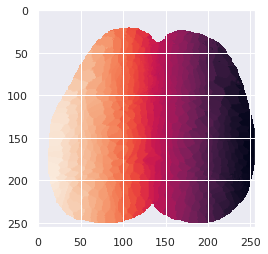

In [8]:
with h5py.File(config_root+'idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [9]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

cm126_2_runI_stim_1  2
cm126_2_runG_stim_1  12
cm126_2_runJ_stim_1  9
cm126_2_runH_stim_1  7
whisking velocity missing  cm126_2_runE
whisking velocity missing  cm126_2_runC
whisking velocity missing  cm126_2_runD
cm126_2_runB_stim_1  2
cm126_2_runF_stim_1  2
cm126_3_runI_stim_1  3
cm126_3_runG_stim_1  9
cm126_3_runJ_stim_1  3
cm126_3_runH_stim_1  2
cm126_3_runE_stim_1  25
cm126_3_runC_stim_1  5
rotf missing  cm126_3_runD  
cm126_3_runB_stim_1  9
cm126_3_runF_stim_1  8
cm126_1_runI_stim_1  1
cm126_1_runG_stim_1 no start_stop_ind
cm126_1_runJ_stim_1 no start_stop_ind
cm126_1_runH_stim_1  1
rotf missing  cm126_1_runE  
rotf missing  cm126_1_runC  
rotf missing  cm126_1_runD  
cm126_1_runB_stim_1 no start_stop_ind
cm126_1_runF_stim_1  2


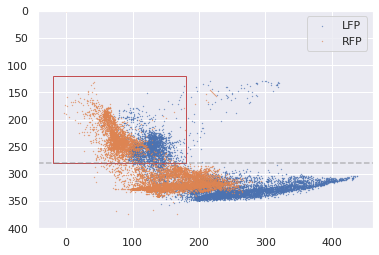

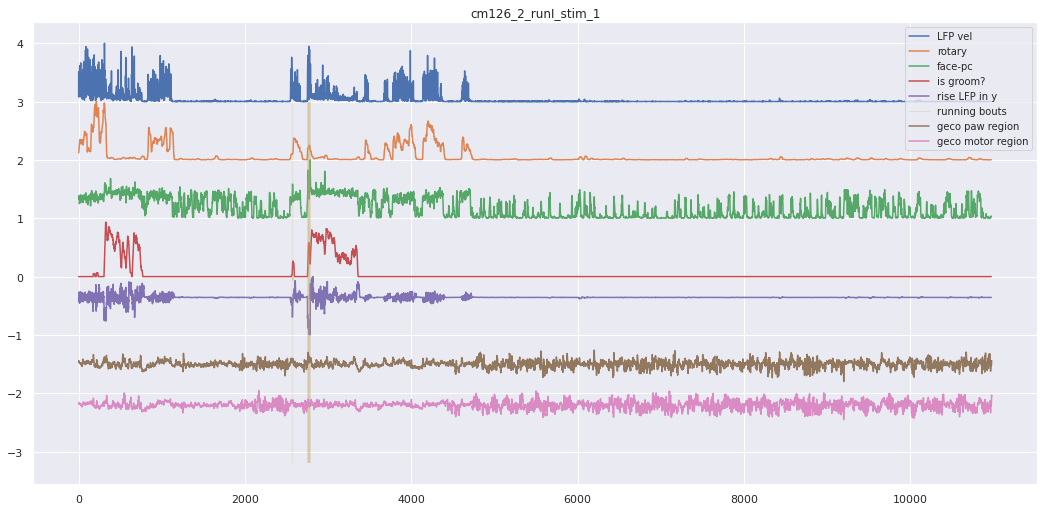

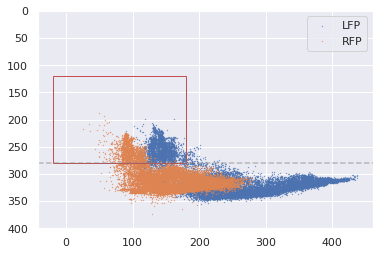

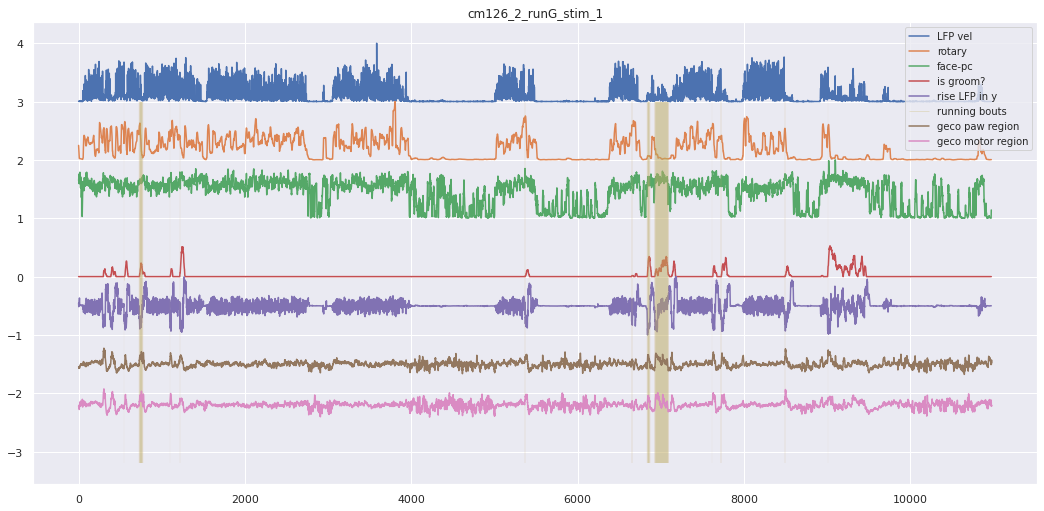

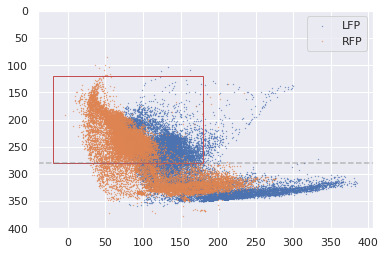

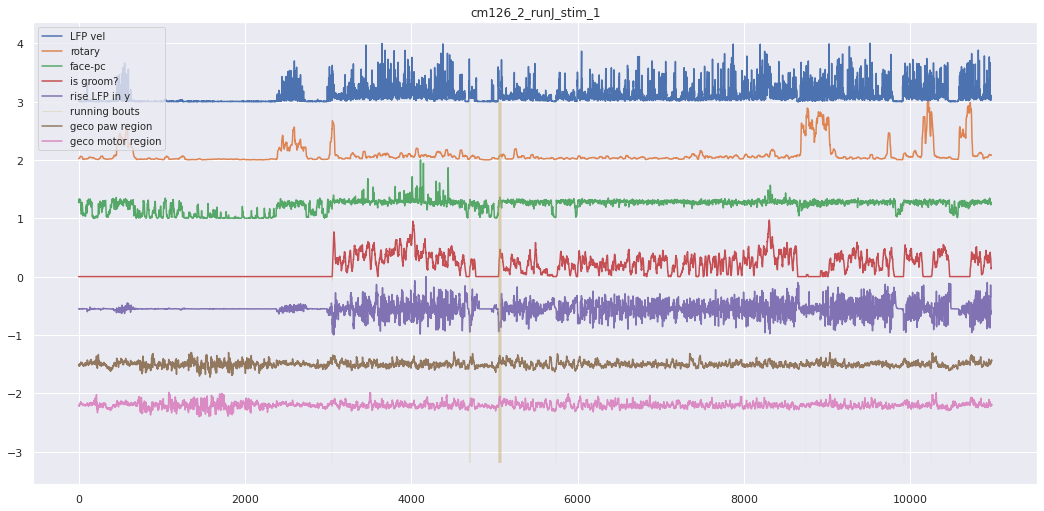

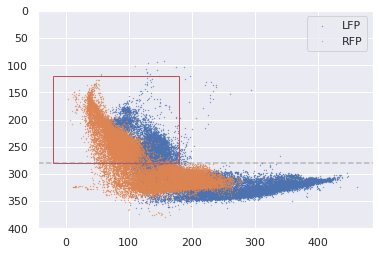

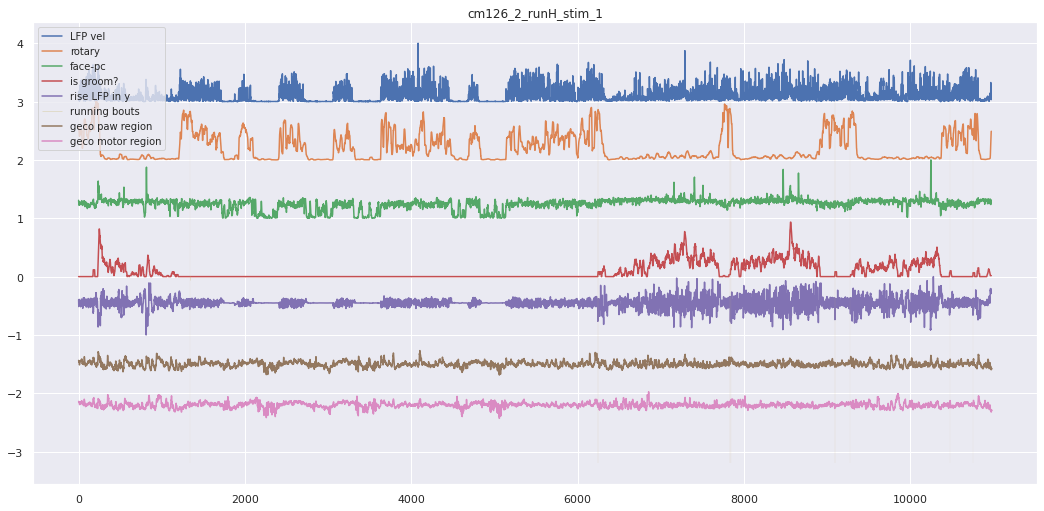

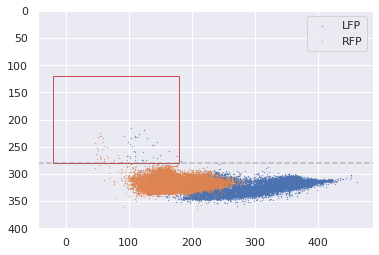

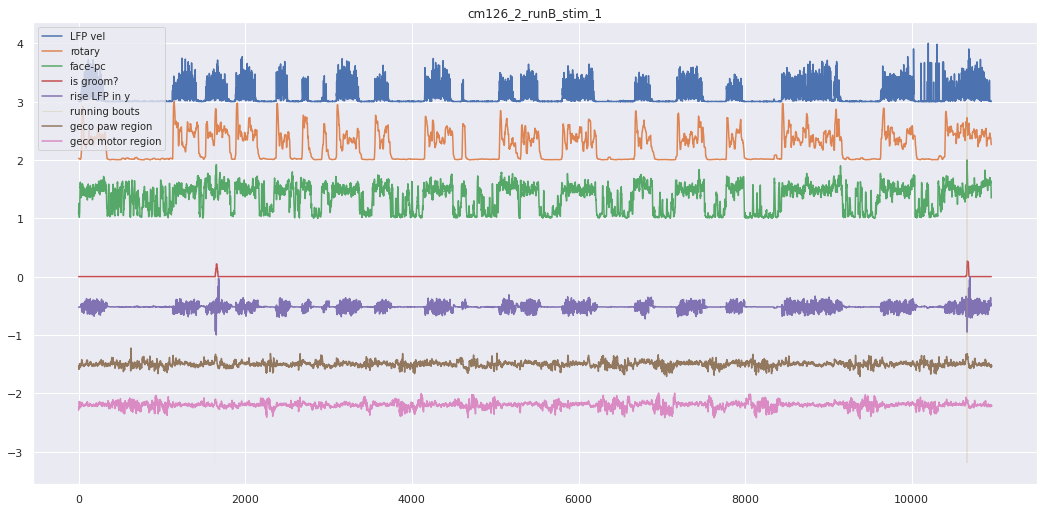

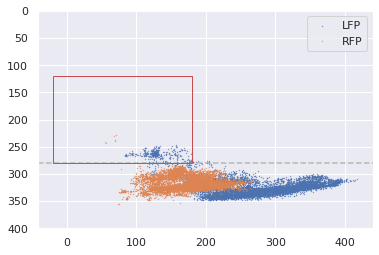

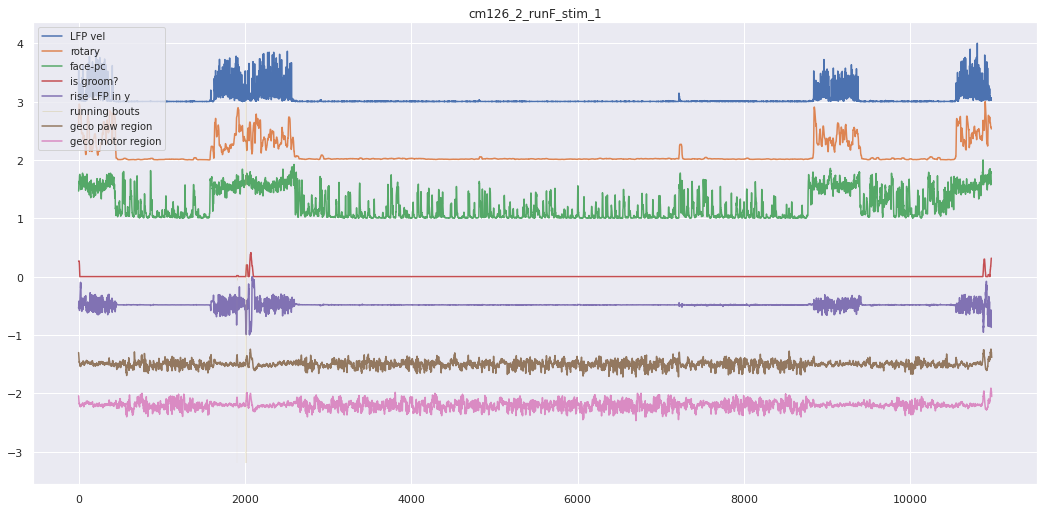

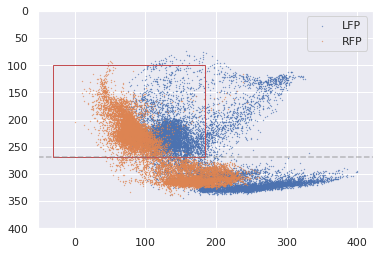

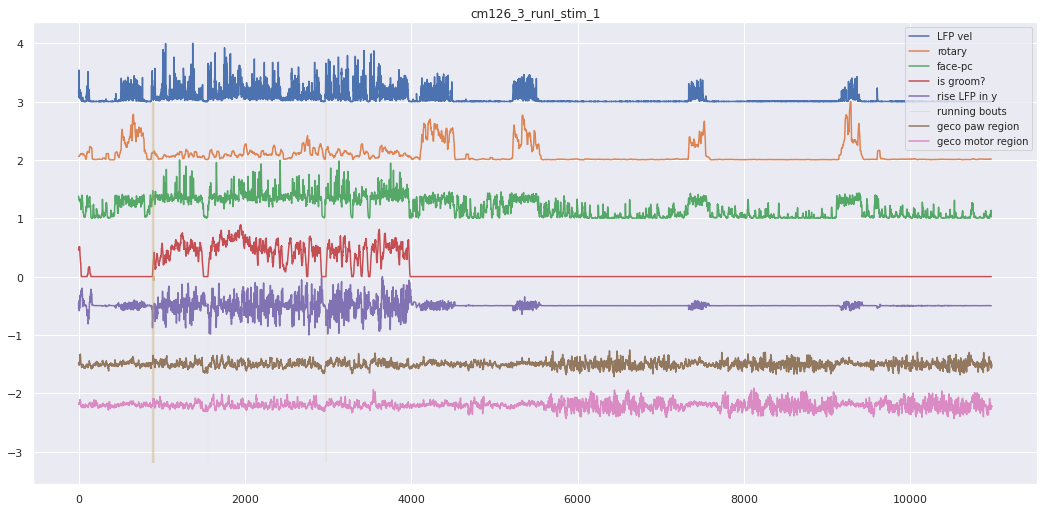

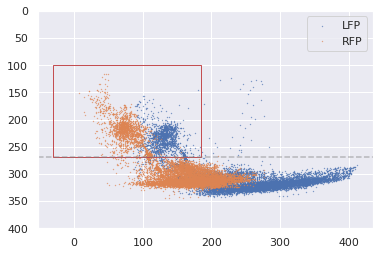

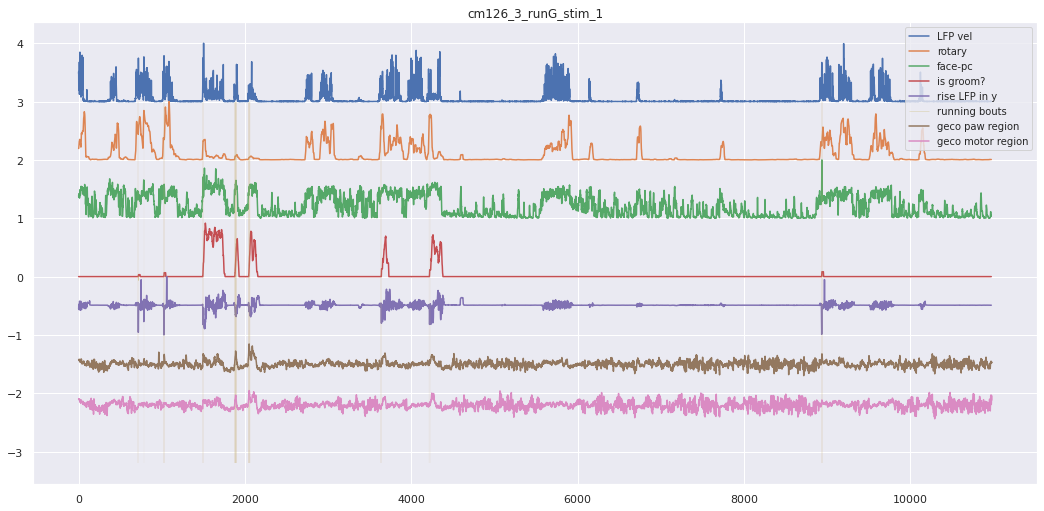

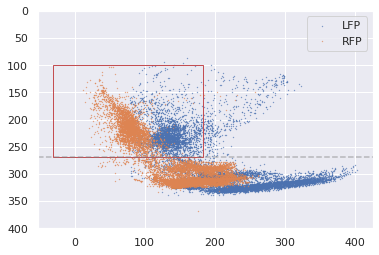

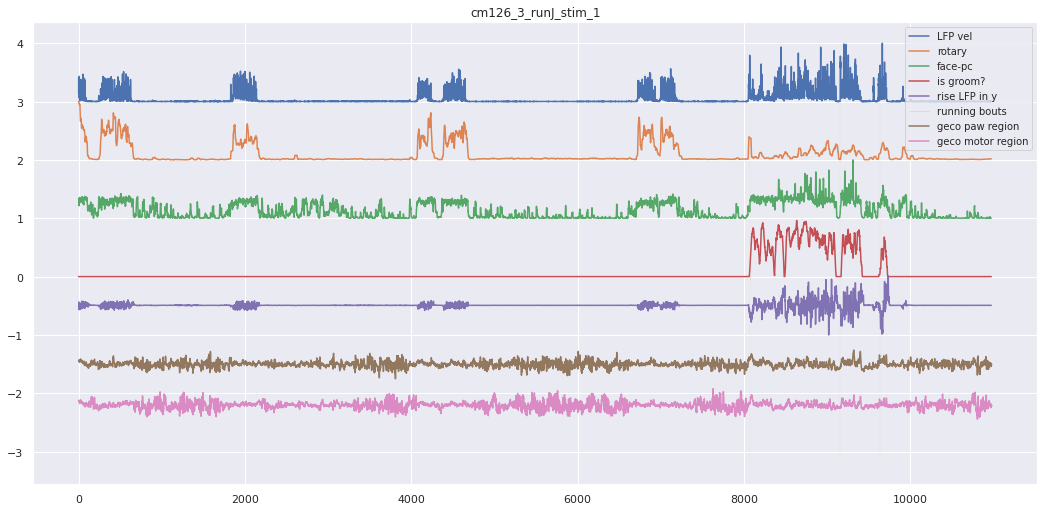

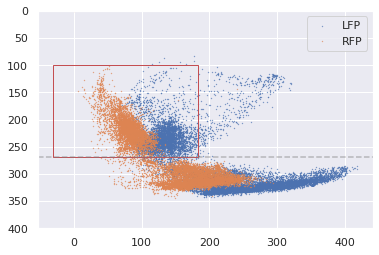

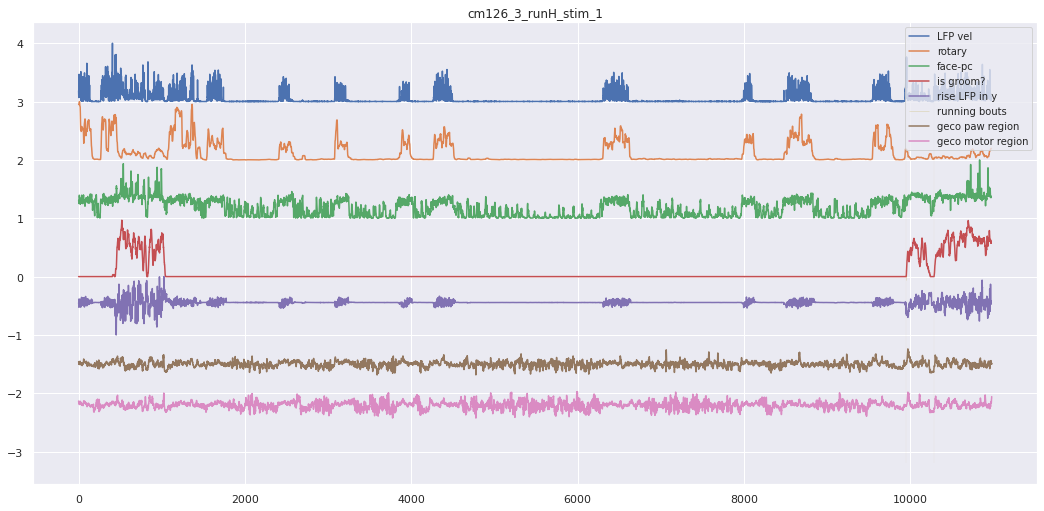

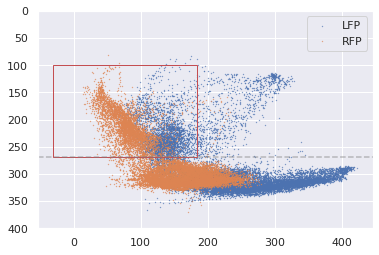

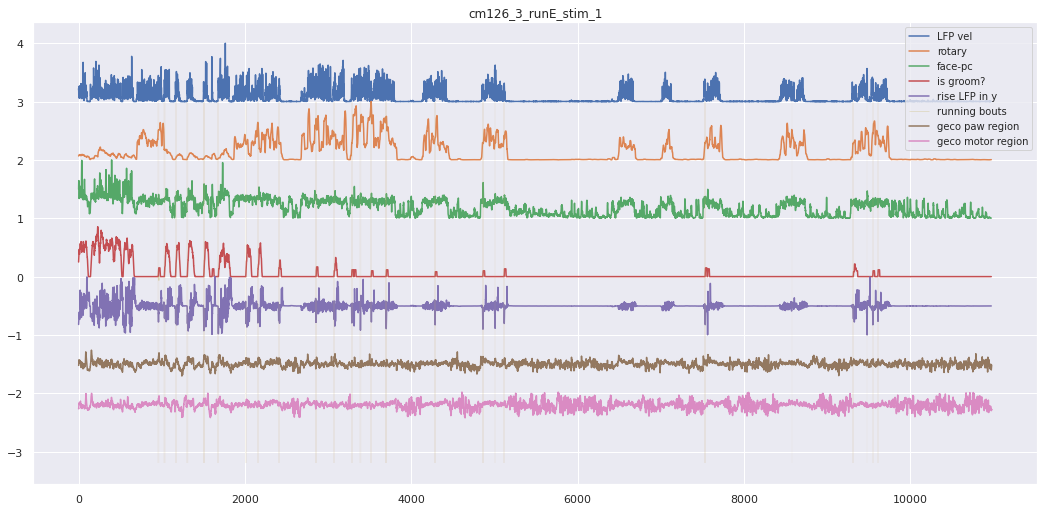

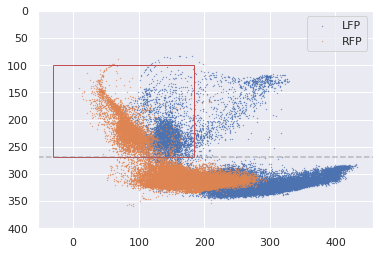

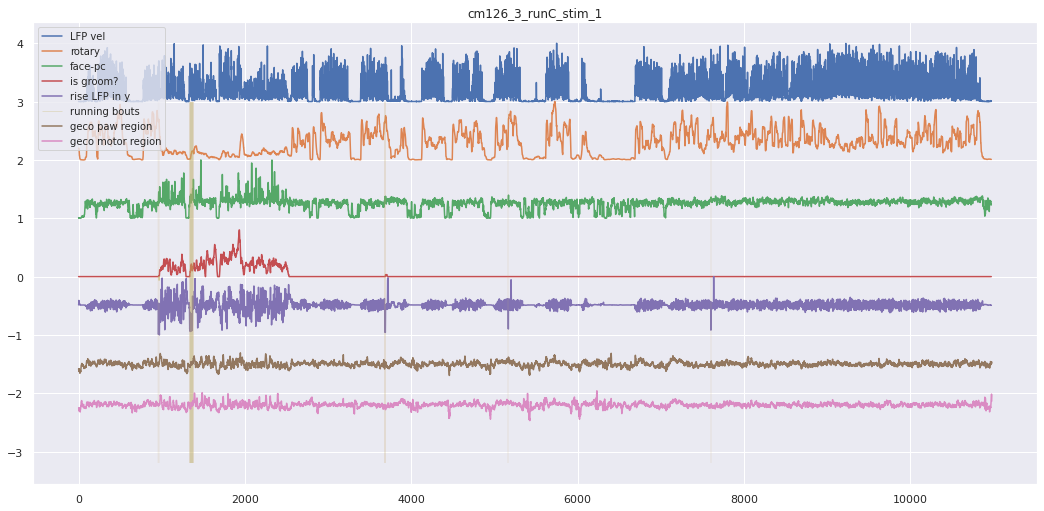

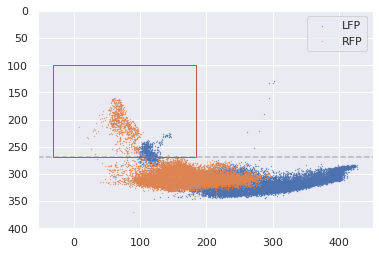

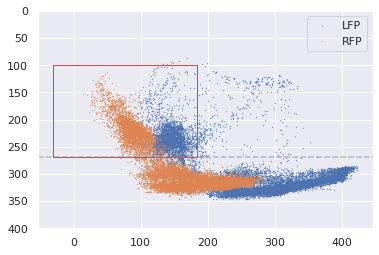

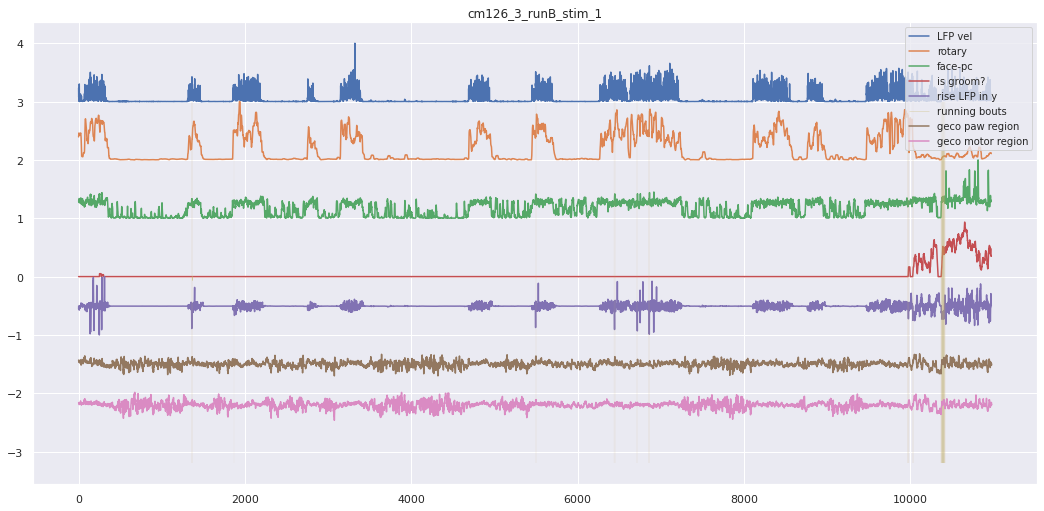

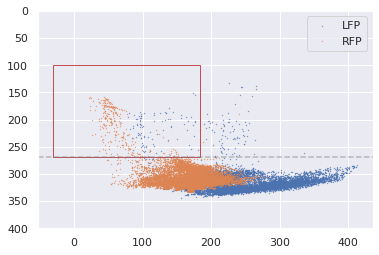

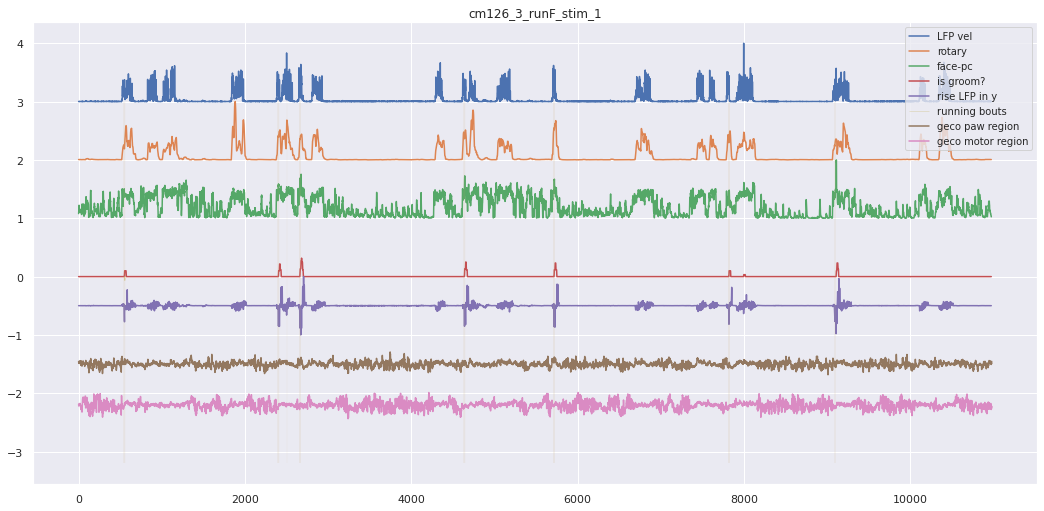

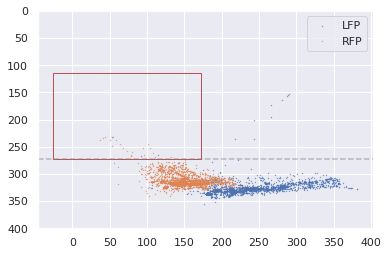

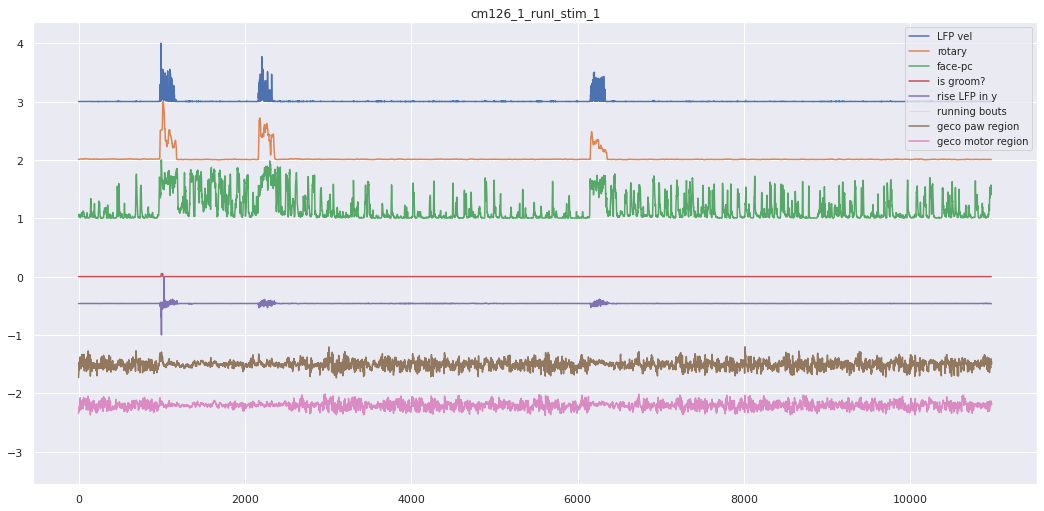

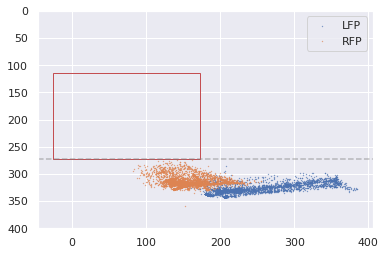

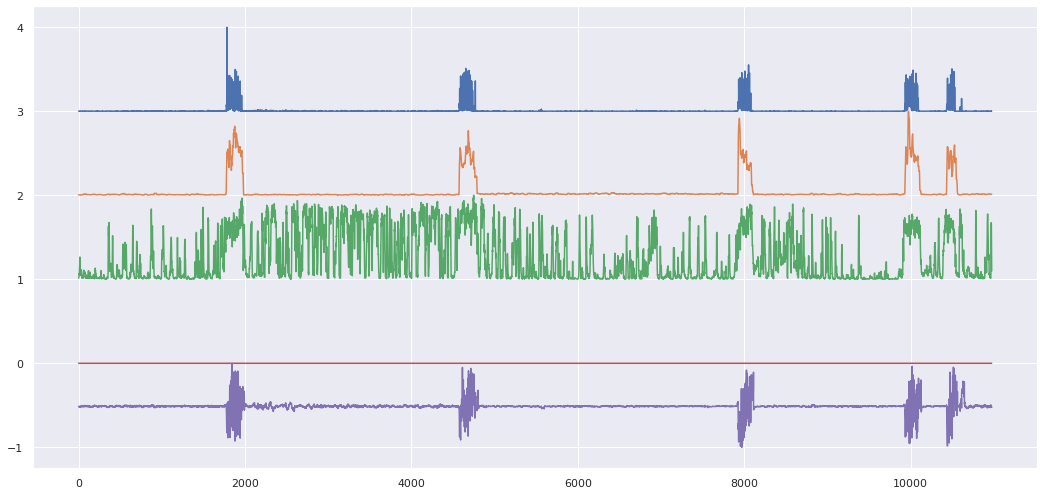

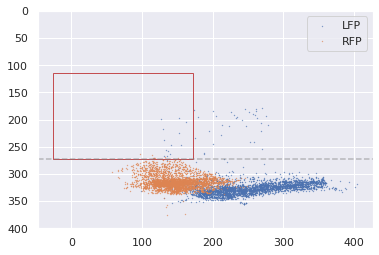

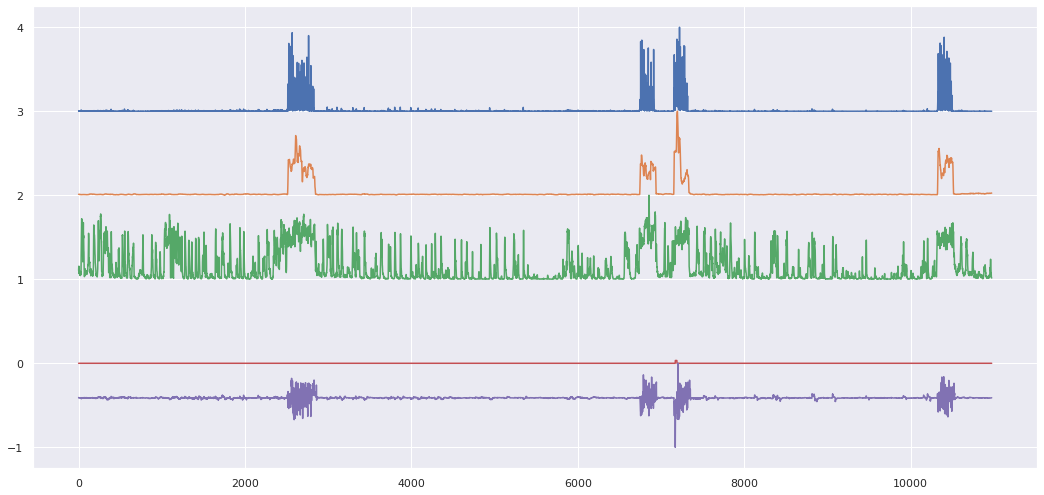

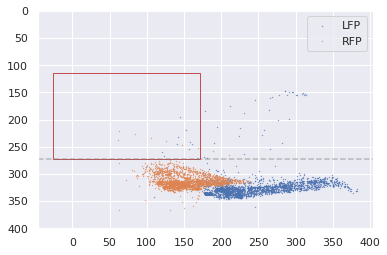

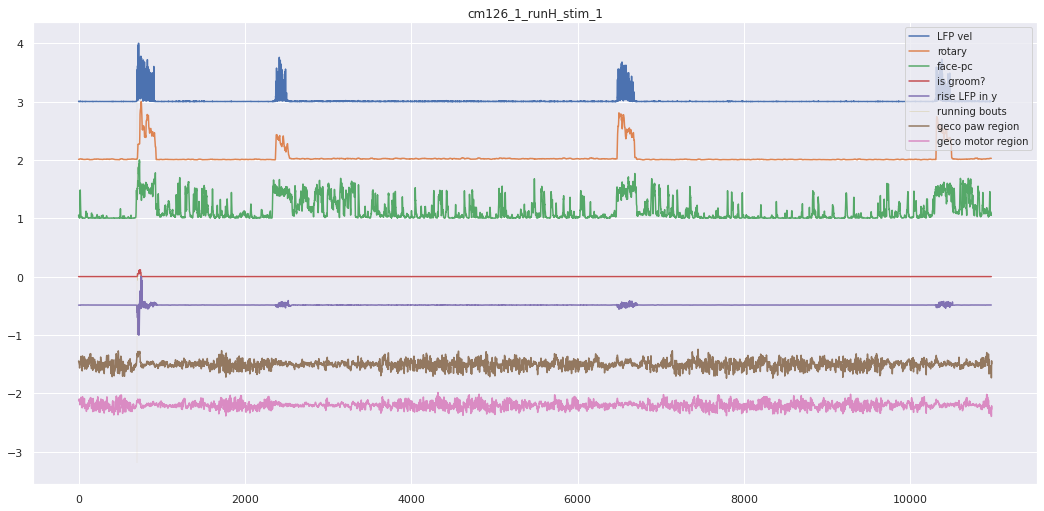

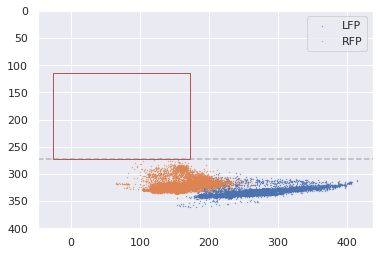

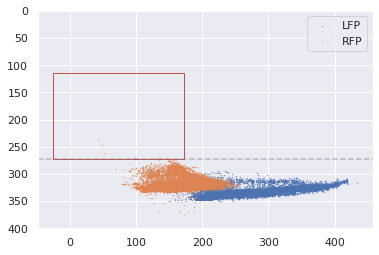

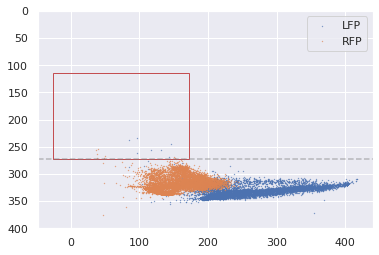

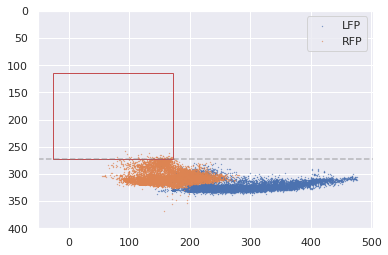

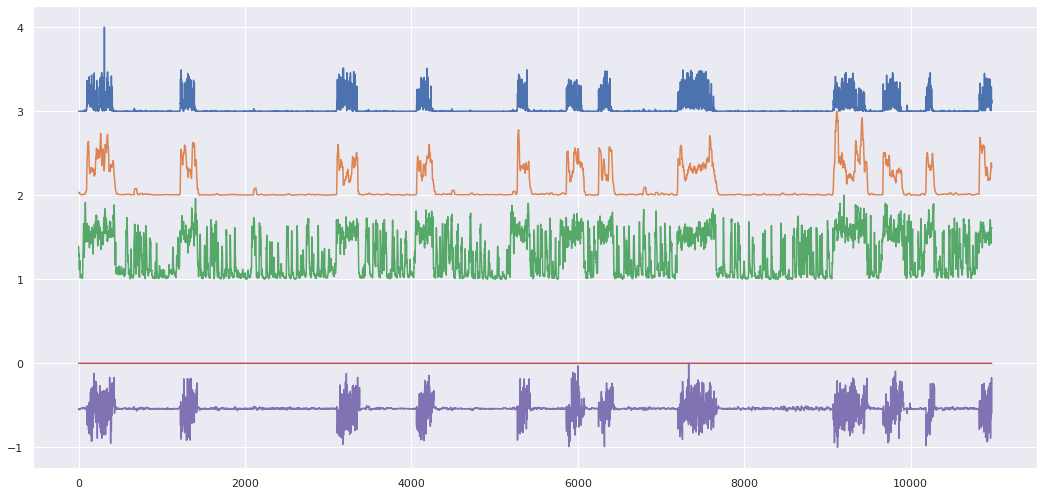

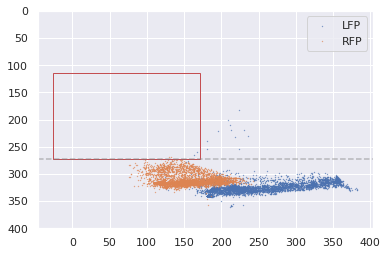

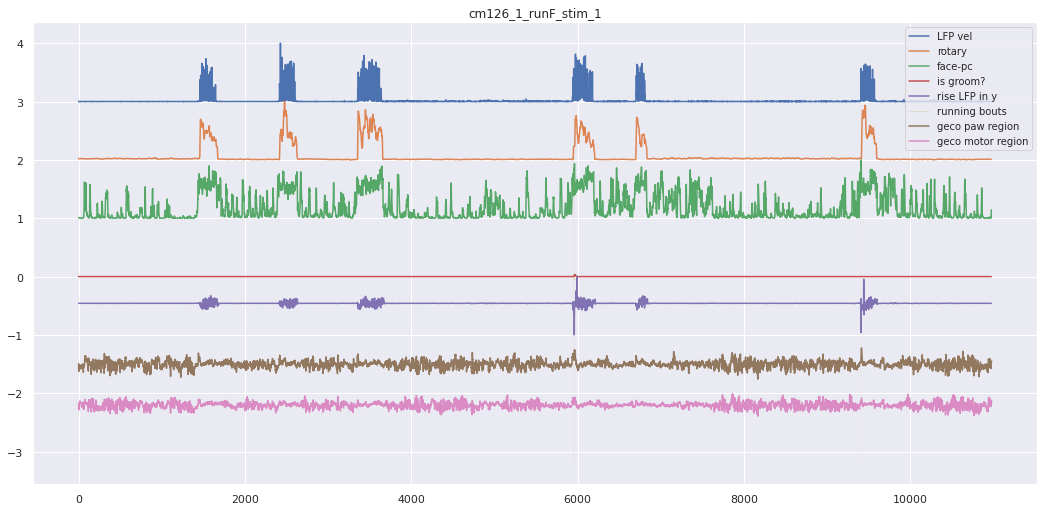

In [10]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 500
T_POST = 100
T=T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = np.empty((num_regions,T,0))
M_jrgeco_std = np.empty((num_regions,T,0))
# M_chbt = np.empty((num_regions,T,0))
# M_chbt_std = np.empty((num_regions,T,0))
M_rotf = np.empty((T,0))
M_rotf_raw = np.empty((T,0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_whisk_vel = np.empty((T,0))
M_whisk_vel_norm = np.empty((T,0))
M_nose_vel = np.empty((T,0))
M_nose_vel_norm = np.empty((T,0))
M_day_label = np.empty((0))
M_is_groom = np.empty((T,0))
M_ind = np.empty((0))
M_y_rise_LFP = np.empty((T,0))
M_y_rise_LFP_raw = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_LFP_vel_norm = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_RFP_vel_norm = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))

data_joint=pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    f = h5py.File(fname,'r')
    ################################### identity 
    run_name = fname[-15:-4]
    mouse = fname[-25:-20]
    day = fname[-19:-18]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]

    try:
        with h5py.File(pjoin(neural_root,mouse,day,'H_'+run+'_stim_1.mat'),'r') as f_H: 

            H = np.array(f_H['H']).transpose() #(36,11975)
            H = H[:,500:-500]
            
    except:
        print('missing',mouse,day,'H_'+run+'_stim_1.mat')
        continue
        
    
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(whisk_dlc_root+'face/' + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(15).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(15).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin('/home/wx2203/RS_analysis/behavior',
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].rolling(window=5,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        continue

    # 
    try:
        paws_vel_df = pd.DataFrame()
        f_name_dlc = glob.glob(mirror_dlc_root + mouse_day[2:]+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        #     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        bodyparts=['LFP','RFP','LHP','RHP']
        for i_bpt,bpt in enumerate(bodyparts):
            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.07]=np.nan
            new_df[bpt]['y'][p_value<0.07]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # nan appears in first few rows

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel)
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])
        #downsample
        new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
        df_cam1 = new_df.iloc[500:-505]

    except:
        print('mirror paws velocity missing ',mouse_day+'_'+run)
        continue        
     
        
#     try:    
    f_config = h5py.File(config_root+'groom_config_'+mouse+'.mat','r')

    x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
    x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
    y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
    y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]

    out_h = int((x_botton_right - x_top_left)/3)
    out_w = int((y_botton_right - y_top_left)/3) + 30
    y = int(x_top_left/3)
    x = int(y_top_left/3)-50 # wider

    f_name_dlc = glob.glob(groom_dlc_root +mouse+'/'+ mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    paws_vel_no_ds_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
    for i_bpt,bpt in enumerate(bodyparts):

        p_value = new_df[bpt]['likelihood']
        new_df[bpt]['x'][p_value<0.07]=np.nan
        new_df[bpt]['y'][p_value<0.07]=np.nan
        new_df[bpt] = new_df[bpt].interpolate()
        new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        paws_vel_no_ds_df[bpt] = vel
        vel = pd.DataFrame(vel)#.rolling(15).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]
    LFP_vel = np.array(paws_vel_df['LFP'])
    RFP_vel = np.array(paws_vel_df['RFP'])


    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,400])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()
    plt.axhline(int(x_botton_right/3),linestyle='--',alpha=0.5,color='gray')
    
    rise_LFP = new_df['LFP']['y'].copy().diff().rolling(100).mean()
    rise_LFP = np.mean(rise_LFP[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

    rise_LFP_raw = new_df['LFP']['y'].copy().diff()
    rise_LFP_raw = np.mean(rise_LFP_raw[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP_raw = rise_LFP_raw[500:-505]   

    is_LFP_in = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_LFP_move = np.array(stats.zscore(paws_vel_no_ds_df['LFP'],nan_policy='omit'))>0.1
    is_groom = np.logical_and(is_LFP_in,is_LFP_move)
    is_groom_smooth = is_groom.rolling(60).mean()

    is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    #downsample
    new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
    df_cam0 = new_df.iloc[500:-505]


#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue

    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(face_pc.values)
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(body_pc.values)    
    whisk_vel_norm = stats.zscore(whisk_vel)
    nose_vel_norm = stats.zscore(nose_vel)
    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)

        
    ################################### rotary (11980, 1)
    try:
        with h5py.File(rotary_root+mouse_day+'_'+run+'_H.mat','r') as f_rot:
            rotf = pd.DataFrame((f_rot['rotf'])).rolling(window=30,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   

            rotf = stats.zscore(rotf.values)

            rotf_raw = stats.zscore(np.array(f_rot['rotf']))      
            rotf_raw = rotf_raw[500:-505]
            rotf_raw = stats.zscore(rotf_raw)
    except:
        print('rotf missing ',mouse_day+'_'+run,' ')
        # # No rotf file found? Use body_pc instead..
        # rotf = body_pc.copy()
        # rotf_raw = rotf  
        continue
        


    crossing_the_line = df_cam0['LFP']['y'].values < int(x_botton_right/3)
    
    ################### plotting stuffs + ***[start_stop_ind]***
#     running_ind = rotf>1
    start_stop_ind = pd.DataFrame(start_stop(np.squeeze(crossing_the_line),trigger_val = True))
    start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
    start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
    start_stop_ind = start_stop_ind.fillna(100000) # save the first bout
    start_stop_ind = start_stop_ind[start_stop_ind['distance_difference']>50]
    # start_stop_ind = start_stop_ind[start_stop_ind['duration']>30]
    start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE+1]
    start_stop_ind = start_stop_ind[start_stop_ind[0]<10970-(T_POST)]

    try:
        plt.figure(figsize=(18,8.5))
        plt.plot(normalize(LFP_vel_norm)+3,label='LFP vel')
        plt.plot(normalize(rotf)+2,label='rotary')
        plt.plot(normalize(face_pc)+1,label='face-pc')
        plt.plot(is_groom_smooth_ds,label='is groom?')
        plt.plot(rise_LFP-1,label='rise LFP in y')
        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -3.2, 3,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')

        plt.title(mouse_day+'_'+run_name)
        plt.plot(H[134,:]*3-1.5,label='geco paw region')
        plt.plot(H[73,:]*3-2.2,label='geco motor region')
        plt.legend(fontsize = 10)
        print(mouse_day+'_'+run_name,' '+str(len(start_stop_ind)))
    except:
        print(mouse_day+'_'+run_name+' no start_stop_ind')
        continue

    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        
        M_rotf_raw = np.append(M_rotf_raw,rotf_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rotf[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel = np.append(M_whisk_vel,whisk_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel = np.append(M_nose_vel,nose_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel_norm = np.append(M_nose_vel_norm,nose_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel_norm = np.append(M_RFP_vel_norm,RFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
                    
        i_bout = M_jrgeco.shape[-1]-1 # start from 0      
        tmp = data_pot[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST]
        tmp = pd.concat([tmp], keys=[i_bout], names=['row_level'])
        data_joint = data_joint.append(tmp)
        
        
        M_mirrorLFP_vel = np.append(M_mirrorLFP_vel,mirrorLFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLFP_vel_norm = np.append(M_mirrorLFP_vel_norm,mirrorLFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel = np.append(M_mirrorRFP_vel,mirrorRFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel_norm = np.append(M_mirrorRFP_vel_norm,mirrorRFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel = np.append(M_mirrorLHP_vel,mirrorLHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel_norm = np.append(M_mirrorLHP_vel_norm,mirrorLHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel = np.append(M_mirrorRHP_vel,mirrorRHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel_norm = np.append(M_mirrorRHP_vel_norm,mirrorRHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_ind = np.append(M_ind,start_stop_ind.iloc[i,0]*3+1500)
        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_y_rise_LFP = np.append(M_y_rise_LFP,rise_LFP[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_y_rise_LFP_raw = np.append(M_y_rise_LFP_raw,rise_LFP_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


In [11]:
print(M_jrgeco.shape,
M_jrgeco_std.shape,
M_body_pc.shape,
M_face_pc.shape)

(500, 600, 102) (500, 600, 0) (600, 102) (600, 102)


In [12]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
    

In [13]:
scipy.io.savemat(prefix+'users/wx2203/new_analysis_locker/pub-locker/motif/'+mouse+'_raw.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind':M_ind,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                       'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
                       })


save_model(data_joint,prefix+'users/wx2203/new_analysis_locker/pub-locker/motif/'+mouse+'_raw_data_joint')